# Regressão do engajamento estudantil com Spark ML
### OULAD — amostra aleatória de **exatamente 200.000 registros**

**Disciplina:** Processamento de Dados Massivos  
**Professor:** Alexandre Roriz  
**Tipo de problema:** **Regressão**  
**Aluno:** Kaike Armond Costa

> **Questão central:** Com base na disciplina, oferta, tipo de recurso e momento do curso,
> é possível estimar o número de cliques que um estudante realiza em determinado material
> do ambiente virtual de aprendizagem em um dia?

O CSV original é baixado **uma vez**, mas uma amostra
uniforme, sem reposição, de **200.000 linhas** é criada por streaming antes de iniciar
as análises no Spark. **O Spark lê e processa apenas a amostra**, não os 10,6 milhões
de registros originais. A amostra fica em cache local para próximas execuções.

**Etapas:** contextualização → ingestão → exploração e limpeza → engenharia de atributos
→ treinamento e ajuste → avaliação → persistência → conclusão.


## 1. Contextualização e justificativa de dados massivos

### Base de dados
**OULAD — Open University Learning Analytics Dataset**, publicada pela The Open University,
e disponibilizada publicamente no Kaggle. Registros de cursos e interações em ambiente
virtual de aprendizagem (*Virtual Learning Environment*, VLE) relativos a **2013–2014**.

- **Kaggle:** https://www.kaggle.com/datasets/rocki37/open-university-learning-analytics-dataset
- **Fonte primária:** https://research.stem.open.ac.uk/ouanalyse/dataset/
- **Artigo de referência:** https://doi.org/10.1038/sdata.2017.171
- **Licença da fonte primária:** CC BY 4.0.

Na versão publicada, o arquivo **`studentVle.csv` tem 10.655.280 registros e 6 colunas**,
e o **`vle.csv` tem 6.364 registros**. O notebook apura o número de registros do CSV
recebido pelo download, pois a versão de um espelho pode variar.

**Unidade observacional:** estudante × curso × oferta × material × dia relativo ao início.  
**Variável-alvo (regressão):** `sum_click` (contagem de cliques por observação).  
**Preditores:** disciplina, oferta, tipo de atividade e momento relativo do curso.

### Por que o problema é de dados massivos?
Na operação real de uma plataforma educacional, os acessos chegam continuamente
(**velocidade**), envolvem muitos cursos e recursos (**variedade**) e produzem
milhões de registros (**volume**). Em escala institucional, consolidar eventos,
combinar metadados e atualizar previsões demanda particionamento, processamento
paralelo e pipelines repetíveis — capacidades do Spark. A amostra é apenas um
**recorte didático por limitação de tempo e hardware**; os dados originais e o
problema real continuam massivos. O exercício não afirma que 200 mil linhas
exijam obrigatoriamente um cluster distribuído.

### Amostragem — tamanho e método declarados
A população é o **CSV original inteiro** (`studentVle.csv`; aproximadamente
10,65 milhões de registros). Será extraída uma **amostra aleatória simples
sem reposição, de 200.000 registros**, com semente fixa **42**.

- Sorteia **exatamente 200.000 índices distintos** uniformemente entre as linhas
  da população e grava apenas esses registros num CSV menor, preservando o cabeçalho.
- O Spark faz **ingestão, exploração, limpeza, engenharia e modelagem apenas no CSV
  amostrado**.
- A amostragem é por **registro**, não por aluno. Portanto, preserva a distribuição
  dos registros mais diretamente, mas pode deixar o histórico de cada estudante
  incompleto. Isso é aceitável porque **nenhum atributo histórico individual**
  é calculado; o particionamento de treino e teste ainda é **por estudante**.
- Depois da limpeza ou consolidação de chaves, o número de registros usados na
  modelagem pode ser **ligeiramente inferior a 200 mil**. Essa diferença será medida.


## 2. Ambiente e download reproduzível

Execute as células na ordem no Google Colab ou Jupyter. Na primeira execução,
é necessário baixar a base original e criar a amostra; **essa transferência inicial
continua dependendo da velocidade da internet**. Depois, a amostra de 200 mil
linhas é reutilizada da pasta `dados_locais/` na mesma sessão.

O **notebook não publica CSV no GitHub**. Ao rodar, ele baixa a fonte aberta
pelo KaggleHub ou, se necessário, pelo arquivo oficial da UCI.


In [49]:
import importlib.util
import subprocess
import sys

pacotes = []
if importlib.util.find_spec("pyspark") is None:
    pacotes.append("pyspark==4.0.1")
if importlib.util.find_spec("kagglehub") is None:
    pacotes.append("kagglehub>=0.3.0")
if importlib.util.find_spec("matplotlib") is None:
    pacotes.append("matplotlib>=3.8")
if pacotes:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pacotes])
print("Dependências disponíveis.")

Dependências disponíveis.


In [50]:
from pathlib import Path
import json
import shutil
import zipfile
import urllib.request
import matplotlib.pyplot as plt
import kagglehub

from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import StructType, StructField, StringType, IntegerType
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.regression import LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator

SEMENTE = 42
TAMANHO_AMOSTRA = 200_000
spark = (
    SparkSession.builder
    .appName("Educacao_OULAD_200mil_Regressao_SparkML")
    .master("local[2]")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.ui.enabled", "false")
    .config("spark.driver.memory", "4g")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version, "| execução:", spark.sparkContext.master)


Spark 4.0.5 | execução: local[2]


In [51]:
# Fonte pública: Kaggle; contingência: repositório oficial UCI.
KAGGLE_DATASET = "rocki37/open-university-learning-analytics-dataset"
UCI_ZIP = "https://archive.ics.uci.edu/static/public/349/open+university+learning+analytics+dataset.zip"
PASTA_DADOS = Path("dados_locais")
PASTA_DADOS.mkdir(exist_ok=True)

try:
    pasta_fonte = Path(kagglehub.dataset_download(KAGGLE_DATASET))
    origem_efetiva = f"Kaggle: {KAGGLE_DATASET}"
except Exception as erro_kaggle:
    print("Kaggle indisponível; utilizando o arquivo oficial UCI:", str(erro_kaggle)[:180])
    arquivo_zip = PASTA_DADOS / "oulad_oficial.zip"
    if not arquivo_zip.exists():
        urllib.request.urlretrieve(UCI_ZIP, arquivo_zip)
    pasta_fonte = PASTA_DADOS / "oulad_oficial"
    pasta_fonte.mkdir(exist_ok=True)
    with zipfile.ZipFile(arquivo_zip) as pacote:
        pacote.extractall(pasta_fonte)
    origem_efetiva = f"UCI (fonte primária): {UCI_ZIP}"

# Localiza CSVs inclusive se a distribuição vier em arquivos ZIP aninhados.
def encontrar_arquivo(pasta, nome):
    pasta = Path(pasta)
    for _ in range(3):
        candidatos = [p for p in pasta.rglob("*") if p.is_file() and p.name.lower() == nome.lower()]
        if candidatos:
            return candidatos[0]
        zips = list(pasta.rglob("*.zip"))
        if not zips:
            break
        extraiu = False
        for arquivo in zips:
            destino = arquivo.parent / (arquivo.stem + "_extraido")
            if not destino.exists():
                destino.mkdir(parents=True)
                with zipfile.ZipFile(arquivo) as pacote:
                    pacote.extractall(destino)
                extraiu = True
        if not extraiu:
            break
    raise FileNotFoundError(f"CSV {nome} não encontrado em {pasta}.")

csv_interacoes_original = encontrar_arquivo(pasta_fonte, "studentVle.csv")
csv_recursos = encontrar_arquivo(pasta_fonte, "vle.csv")
print("Fonte:", origem_efetiva)
print("Arquivo populacional:", csv_interacoes_original.name)
print("Metadados:", csv_recursos.name)


Using Colab cache for faster access to the 'open-university-learning-analytics-dataset' dataset.
Fonte: Kaggle: rocki37/open-university-learning-analytics-dataset
Arquivo populacional: studentVle.csv
Metadados: vle.csv


In [52]:
# AMOSTRA ALEATÓRIA SIMPLES EXATA — execução em streaming, sem Spark no CSV de 10M.
# O dataset OULAD studentVle.csv é tabular: cada observação ocupa uma linha física.
# Amostragem uniforme de linhas, sem reposição, com semente fixa 42.
import os
import random

csv_amostra = PASTA_DADOS / "studentVle_amostra_200000.csv"
manifesto_amostra = PASTA_DADOS / "amostra_200000_manifesto.json"

# Conta as linhas em blocos de bytes: rápido, com memória limitada.
def contar_linhas_binario(caminho, bloco=8 * 1024 * 1024):
    quantidade = 0
    ultimo_byte = b""
    with open(caminho, "rb") as arquivo:
        while True:
            dados = arquivo.read(bloco)
            if not dados:
                break
            quantidade += dados.count(b"\n")
            ultimo_byte = dados[-1:]
    if ultimo_byte and ultimo_byte != b"\n":
        quantidade += 1
    return quantidade

# Permite ignorar a amostragem caso a mesma fonte já tenha sido processada.
identidade_fonte = {
    "origem_arquivo": str(csv_interacoes_original.resolve()),
    "tamanho_em_bytes": csv_interacoes_original.stat().st_size,
    "tamanho_amostra": TAMANHO_AMOSTRA,
    "semente": SEMENTE,
}
usar_cache = False
if csv_amostra.exists() and manifesto_amostra.exists():
    try:
        metadados = json.loads(manifesto_amostra.read_text(encoding="utf-8"))
        usar_cache = all(metadados.get(k) == v for k, v in identidade_fonte.items())
        usar_cache = usar_cache and metadados.get("linhas_amostradas") == TAMANHO_AMOSTRA
    except (ValueError, OSError):
        usar_cache = False

if usar_cache:
    n_original = int(metadados["linhas_original"])
    print("Amostra de 200 mil localizada no cache: sem novo sorteio.")
else:
    n_original = contar_linhas_binario(csv_interacoes_original) - 1  # retira o cabeçalho
    if n_original < TAMANHO_AMOSTRA:
        raise ValueError(f"Fonte com apenas {n_original} linhas, abaixo das 200 mil exigidas.")

    # Sorteia apenas índices inteiros; não carrega linhas do CSV inteiro na memória.
    indices_sorteados = sorted(random.Random(SEMENTE).sample(range(n_original), TAMANHO_AMOSTRA))
    caminho_temporario = csv_amostra.with_suffix(".temporario")
    with open(csv_interacoes_original, "rb") as origem, open(caminho_temporario, "wb") as destino:
        cabecalho = origem.readline()
        destino.write(cabecalho)
        posicoes = iter(indices_sorteados)
        proxima_posicao = next(posicoes, None)
        linhas_copiadas = 0
        for indice, linha in enumerate(origem):
            if indice == proxima_posicao:
                destino.write(linha)
                linhas_copiadas += 1
                proxima_posicao = next(posicoes, None)
                if proxima_posicao is None:
                    break

    assert linhas_copiadas == TAMANHO_AMOSTRA, "Não foi possível selecionar exatamente 200 mil."
    os.replace(caminho_temporario, csv_amostra)
    metadados = dict(identidade_fonte, linhas_original=n_original,
                     linhas_amostradas=linhas_copiadas,
                     metodo="AAS de linhas sem reposicao, random.sample, seed=42")
    manifesto_amostra.write_text(json.dumps(metadados, indent=2), encoding="utf-8")
    print("Nova amostra aleatória de 200 mil linhas criada e salva em cache.")

print(f"População: {n_original:,} registros | Amostra: {TAMANHO_AMOSTRA:,} "
      f"({100 * TAMANHO_AMOSTRA / n_original:.2f}% do total)")
print("CSV usado pelo Spark:", csv_amostra)


Amostra de 200 mil localizada no cache: sem novo sorteio.
População: 10,655,280 registros | Amostra: 200,000 (1.88% do total)
CSV usado pelo Spark: dados_locais/studentVle_amostra_200000.csv


## 3. Ingestão com esquema manual (`StructType`)

O Spark lê **somente `studentVle_amostra_200000.csv`**, não o CSV original de 10,6
milhões de linhas. A tabela menor de metadados `vle.csv` é usada para adicionar
o tipo de recurso. Especificamos os tipos com **`StructType`** para evitar
inferência e garantir reprodutibilidade.

O campo `date` contém **dias relativos ao início do curso**: dias negativos são
válidos, pois algumas interações acontecem antes do início da oferta.


In [53]:
esquema_interacoes = StructType([
    StructField("code_module", StringType(), True),
    StructField("code_presentation", StringType(), True),
    StructField("id_student", IntegerType(), True),
    StructField("id_site", IntegerType(), True),
    StructField("date", IntegerType(), True),
    StructField("sum_click", IntegerType(), True),
])
esquema_recursos = StructType([
    StructField("id_site", IntegerType(), True),
    StructField("code_module", StringType(), True),
    StructField("code_presentation", StringType(), True),
    StructField("activity_type", StringType(), True),
    StructField("week_from", IntegerType(), True),
    StructField("week_to", IntegerType(), True),
])

interacoes_brutas = (spark.read.option("header", "true").option("mode", "PERMISSIVE")
                    .schema(esquema_interacoes).csv(str(csv_amostra))).cache()
recursos_brutos = (spark.read.option("header", "true").option("mode", "PERMISSIVE")
                  .schema(esquema_recursos).csv(str(csv_recursos)))

n_amostra = interacoes_brutas.count()
n_colunas = len(interacoes_brutas.columns)
n_recursos = recursos_brutos.count()
assert n_amostra == TAMANHO_AMOSTRA, f"Esperados 200.000, encontrados {n_amostra} registros."
print(f"Fonte original: {n_original:,} linhas; CSV AMOSTRADO: {n_amostra:,} linhas, {n_colunas} colunas")
print(f"Metadados dos recursos: {n_recursos:,} linhas")
interacoes_brutas.printSchema()
interacoes_brutas.show(5, truncate=False)


Fonte original: 10,655,280 linhas; CSV AMOSTRADO: 200,000 linhas, 6 colunas
Metadados dos recursos: 6,364 linhas
root
 |-- code_module: string (nullable = true)
 |-- code_presentation: string (nullable = true)
 |-- id_student: integer (nullable = true)
 |-- id_site: integer (nullable = true)
 |-- date: integer (nullable = true)
 |-- sum_click: integer (nullable = true)

+-----------+-----------------+----------+-------+----+---------+
|code_module|code_presentation|id_student|id_site|date|sum_click|
+-----------+-----------------+----------+-------+----+---------+
|AAA        |2013J            |63400     |546667 |-10 |6        |
|AAA        |2013J            |70464     |546667 |-10 |5        |
|AAA        |2013J            |75091     |546874 |-10 |2        |
|AAA        |2013J            |104476    |546667 |-10 |13       |
|AAA        |2013J            |281250    |546662 |-10 |1        |
+-----------+-----------------+----------+-------+----+---------+
only showing top 5 rows


## 4. Exploração e limpeza com funções do Spark — **somente 200 mil linhas**

Todas as verificações (nulos, valores inválidos, estatísticas descritivas e
possíveis chaves repetidas) são realizadas **em Spark** na amostra. Interações
com a mesma combinação estudante × recurso × curso × oferta × dia são agregadas,
somando os cliques, em vez de apagar arbitrariamente eventos possíveis.

A amostra tem **200.000 linhas antes da limpeza**. O tamanho pós-limpeza e
pós-agregação é informado, sem introduzir linhas fictícias.


In [54]:
colunas_obrigatorias = ["code_module", "code_presentation", "id_student", "id_site", "date", "sum_click"]
medidas_qualidade = [
    F.sum(F.when(F.col(c).isNull(), 1).otherwise(0)).alias("nulos_" + c)
    for c in colunas_obrigatorias
]
medidas_qualidade += [
    F.sum(F.when(F.col("sum_click") < 0, 1).otherwise(0)).alias("cliques_negativos"),
    F.sum(F.when(F.trim(F.col("code_module")) == "", 1).otherwise(0)).alias("codigo_vazio"),
    F.sum(F.when(F.trim(F.col("code_presentation")) == "", 1).otherwise(0)).alias("oferta_vazia")
]
print("Auditoria de qualidade na amostra de 200.000 registros:")
interacoes_brutas.agg(*medidas_qualidade).show(truncate=False)
print("Estatísticas descritivas de cliques:")
interacoes_brutas.select("sum_click").describe().show()
print("Distribuição de registros por disciplina:")
interacoes_brutas.groupBy("code_module").count().orderBy(F.desc("count")).show()


Auditoria de qualidade na amostra de 200.000 registros:
+-----------------+-----------------------+----------------+-------------+----------+---------------+-----------------+------------+------------+
|nulos_code_module|nulos_code_presentation|nulos_id_student|nulos_id_site|nulos_date|nulos_sum_click|cliques_negativos|codigo_vazio|oferta_vazia|
+-----------------+-----------------------+----------------+-------------+----------+---------------+-----------------+------------+------------+
|0                |0                      |0               |0            |0         |0              |0                |0           |0           |
+-----------------+-----------------------+----------------+-------------+----------+---------------+-----------------+------------+------------+

Estatísticas descritivas de cliques:
+-------+-----------------+
|summary|        sum_click|
+-------+-----------------+
|  count|           200000|
|   mean|         3.733385|
| stddev|7.678620725615747|
|    min

In [55]:
# Toda a exploração e limpeza a seguir utiliza EXCLUSIVAMENTE os 200 mil registros.
amostra = interacoes_brutas
filtro_validade = (
    F.col("code_module").isNotNull() & (F.trim(F.col("code_module")) != "") &
    F.col("code_presentation").isNotNull() & (F.trim(F.col("code_presentation")) != "") &
    F.col("id_student").isNotNull() & F.col("id_site").isNotNull() &
    F.col("date").isNotNull() & F.col("sum_click").isNotNull() &
    (F.col("sum_click") >= 0)
)
validos = amostra.where(filtro_validade)
n_validos = validos.count()
print("Registros removidos por dados inválidos:", n_amostra - n_validos)

# Verificação de duplicatas por chave, com preservação da soma dos cliques.
CHAVES = ["code_module", "code_presentation", "id_student", "id_site", "date"]
interacoes_consolidadas = validos.groupBy(*CHAVES).agg(
    F.sum("sum_click").cast("double").alias("sum_click")
)
n_consolidadas = interacoes_consolidadas.count()
print(f"Amostra inicial: {n_amostra:,} | válidos: {n_validos:,} | após consolidação: {n_consolidadas:,}")
print(f"Chaves repetidas consolidadas: {n_validos-n_consolidadas:,}")
assert n_consolidadas > 0, "A limpeza removeu todas as observações."


Registros removidos por dados inválidos: 0
Amostra inicial: 200,000 | válidos: 200,000 | após consolidação: 198,837
Chaves repetidas consolidadas: 1,163


In [56]:
# Metadata de pequeno porte; broadcast join evita shuffle desnecessário na amostra.
recurso_dim = (
    recursos_brutos
    .groupBy("id_site", "code_module", "code_presentation")
    .agg(F.first("activity_type", ignorenulls=True).alias("activity_type"))
)
base = (
    interacoes_consolidadas
    .join(F.broadcast(recurso_dim), ["id_site", "code_module", "code_presentation"], "left")
    .fillna({"activity_type": "Desconhecido"})
)
n_base = base.count()
print("Registros após junção:", n_base)
assert n_base == n_consolidadas, "A junção multiplicou linhas indevidamente."
base.groupBy("activity_type").agg(
    F.count("*").alias("registros"),
    F.round(F.avg("sum_click"), 2).alias("media_cliques"),
    F.round(F.stddev("sum_click"), 2).alias("desvio_padrao")
).orderBy(F.desc("registros")).show(25, truncate=False)


Registros após junção: 198837
+-------------+---------+-------------+-------------+
|activity_type|registros|media_cliques|desvio_padrao|
+-------------+---------+-------------+-------------+
|forumng      |44453    |3.33         |4.24         |
|oucontent    |37076    |5.72         |9.14         |
|subpage      |36581    |1.74         |1.54         |
|homepage     |32201    |4.02         |4.41         |
|quiz         |16868    |8.06         |18.81        |
|resource     |15294    |1.36         |4.24         |
|url          |7733     |1.38         |0.95         |
|ouwiki       |3275     |5.07         |7.97         |
|oucollaborate|1237     |1.6          |1.25         |
|externalquiz |955      |1.26         |0.69         |
|page         |879      |1.3          |0.71         |
|questionnaire|873      |1.41         |0.66         |
|ouelluminate |411      |1.56         |1.35         |
|glossary     |339      |4.94         |7.38         |
|dataplus     |232      |3.51         |2.8          

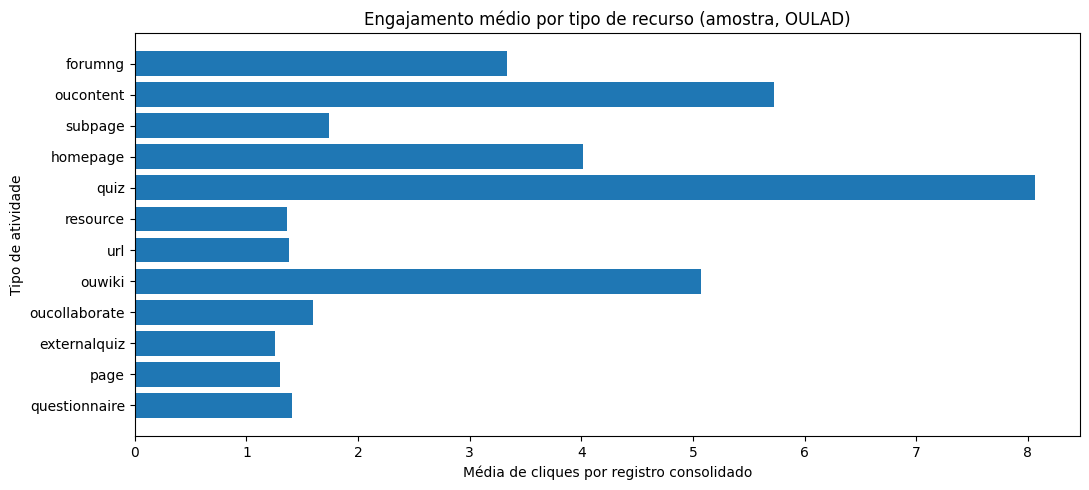

In [57]:
# Visualização com apenas resultado AGREGADO no Spark
tipos_agg = (
    base.groupBy("activity_type")
    .agg(F.count("*").alias("registros"), F.avg("sum_click").alias("media_cliques"))
    .orderBy(F.desc("registros")).limit(12).toPandas()
)
plt.figure(figsize=(11, 5))
plt.barh(tipos_agg["activity_type"][::-1], tipos_agg["media_cliques"][::-1])
plt.xlabel("Média de cliques por registro consolidado")
plt.ylabel("Tipo de atividade")
plt.title("Engajamento médio por tipo de recurso (amostra, OULAD)")
plt.tight_layout()
plt.show()

## 5. Engenharia de atributos e separação de treino/teste

**Preditores anteriores à previsão:** `code_module`, `code_presentation`,
`activity_type` e o dia relativo ao curso. Identificadores de estudante e
material **não** entram no vetor de preditores.

**Atributos derivados:** `semana_relativa`, `pre_curso` e `primeiro_mes`;
`sum_click` é convertido em `label`.

**Controle de vazamento:** embora a amostra tenha sido aleatória **por registro**,
a divisão de dados é feita **por estudante** (aproximadamente 80% treino e 20%
teste, via hash determinístico de `id_student`). O mesmo aluno não fica nos dois
conjuntos. Codificadores, padronização e regressão são ajustados somente no treino.


In [58]:
modelagem = (
    base
    .withColumn("semana_relativa", F.floor(F.col("date") / F.lit(7)).cast("double"))
    .withColumn("pre_curso", F.when(F.col("date") < 0, 1.0).otherwise(0.0))
    .withColumn("primeiro_mes", F.when(F.col("date").between(0, 27), 1.0).otherwise(0.0))
    .withColumn("label", F.col("sum_click").cast("double"))
)
chave_divisao = F.pmod(F.xxhash64(F.col("id_student")), F.lit(100))
treino = modelagem.where(chave_divisao < 80).cache()
teste = modelagem.where(chave_divisao >= 80).cache()
n_treino = treino.count()
n_teste = teste.count()
print(f"Treino: {n_treino:,} | Teste: {n_teste:,} | Total: {n_treino+n_teste:,}")
assert n_treino > 0 and n_teste > 0
assert n_treino+n_teste == n_consolidadas

# Verificação explícita de ausência de estudantes em ambos os conjuntos:
ids_treino = treino.select("id_student").distinct()
ids_teste = teste.select("id_student").distinct()
ids_sobrepostos = ids_treino.join(ids_teste, "id_student", "inner").count()
print("Estudantes repetidos entre treino e teste:", ids_sobrepostos)
assert ids_sobrepostos == 0, "Há vazamento entre treino e teste!"

Treino: 158,886 | Teste: 39,951 | Total: 198,837
Estudantes repetidos entre treino e teste: 0


## 6. Modelo de referência e treinamento em Spark ML

**Baseline:** prever em todas as observações a média dos cliques calculada
**somente no treino**.

**Modelo:** regressão linear com regularização L2 (*Ridge*) implementada pelo
Spark ML. Para **reduzir o tempo de execução**, comparamos **apenas duas**
configurações de regularização (`regParam=0.01` e `0.1`) na validação interna.
O algoritmo usa resolução normal (adequada ao número pequeno de atributos) e
não executa uma grade extensa de hiperparâmetros.

A validação interna também é **separada por estudante**, usando somente o treino.
A configuração de menor RMSE é treinada novamente com todo o treino externo.

**Pipeline:** `StringIndexer` → `OneHotEncoder` → `VectorAssembler` →
`StandardScaler` → `LinearRegression`.


In [59]:
avaliador_rmse = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="rmse")
avaliador_mae  = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="mae")
avaliador_r2   = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="r2")

media_treino = treino.agg(F.avg("label")).first()[0]
pred_base = teste.select("label").withColumn("prediction", F.lit(float(media_treino)))
base_rmse = avaliador_rmse.evaluate(pred_base)
base_mae = avaliador_mae.evaluate(pred_base)
base_r2 = avaliador_r2.evaluate(pred_base)
print(f"BASELINE (média do treino = {media_treino:.3f} cliques):")
print(f"RMSE: {base_rmse:.4f} | MAE: {base_mae:.4f} | R²: {base_r2:.4f}")

BASELINE (média do treino = 3.757 cliques):
RMSE: 7.6437 | MAE: 3.4175 | R²: -0.0000


In [44]:
categoricas = ["code_module", "code_presentation", "activity_type"]
numericas = ["semana_relativa", "pre_curso", "primeiro_mes"]
indexadores = [
    StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep")
    for c in categoricas
]
codificador = OneHotEncoder(
    inputCols=[f"{c}_idx" for c in categoricas],
    outputCols=[f"{c}_oh" for c in categoricas],
    handleInvalid="keep"
)
vetorizador = VectorAssembler(
    inputCols=[f"{c}_oh" for c in categoricas] + numericas,
    outputCol="features_raw", handleInvalid="error"
)
padronizador = StandardScaler(
    inputCol="features_raw", outputCol="features", withStd=True, withMean=False
)

# Validação interna disjunta por aluno, feita SEM usar os dados de teste externo.
chave_interna = F.pmod(F.xxhash64(F.col("id_student")), F.lit(1000))
treino_interno = treino.where(chave_interna < 800).cache()
validacao_interna = treino.where(chave_interna >= 800).cache()
n_treino_int = treino_interno.count()
n_valid_int = validacao_interna.count()
print(f"Treino interno: {n_treino_int:,} | Validação: {n_valid_int:,}")
assert n_treino_int > 0 and n_valid_int > 0

# Um Pipeline completo é estimado novamente para cada regParam.
def pipeline_regressao(reg_param):
    regressor = LinearRegression(
        featuresCol="features", labelCol="label", predictionCol="prediction",
        solver="normal", maxIter=25, tol=1e-4,
        regParam=reg_param, elasticNetParam=0.0
    )
    return Pipeline(stages=indexadores + [
        codificador, vetorizador, padronizador, regressor
    ])

experimentos = []
for reg_param in [0.01, 0.1]:
    candidato = pipeline_regressao(reg_param).fit(treino_interno)
    erro = float(avaliador_rmse.evaluate(candidato.transform(validacao_interna)))
    experimentos.append((erro, reg_param))
    print(f"Validação interna | regParam={reg_param:<5} | RMSE={erro:.4f}")

experimentos.sort(key=lambda x: x[0])
melhor_rmse_val, melhor_reg = experimentos[0]
print(f"Melhor validação: RMSE={melhor_rmse_val:.4f}, regParam={melhor_reg}")

# Teste externo nunca participa do ajuste dos parâmetros ou dos transformadores.
melhor_pipeline = pipeline_regressao(melhor_reg).fit(treino)
modelo_regressao = melhor_pipeline.stages[-1]
print("Pipeline final treinado apenas nos dados de treino externo.")


Treino interno: 127,586 | Validação: 31,300
Validação interna | regParam=0.01  | RMSE=8.2871
Validação interna | regParam=0.1   | RMSE=8.2868
Melhor validação: RMSE=8.2868, regParam=0.1
Pipeline final treinado apenas nos dados de treino externo.


## 7. Avaliação: RMSE, MAE e R² no teste não visto

- **RMSE:** raiz do erro quadrático médio, em **cliques**. Penaliza mais erros grandes.
- **MAE:** erro absoluto médio, em **cliques**. Aproxima o tamanho típico do erro.
- **R²:** parcela da variação do alvo explicada relativamente à previsão pela média;
  pode ser **negativo**. Um R² próximo de zero indica que os atributos testados
  explicam pouco da variação individual.

A comparação com o **baseline** dá contexto às métricas.

In [45]:
predicoes = melhor_pipeline.transform(teste).select(
    "id_student", "code_module", "activity_type", "label", "prediction"
).cache()
rmse = avaliador_rmse.evaluate(predicoes)
mae = avaliador_mae.evaluate(predicoes)
r2 = avaliador_r2.evaluate(predicoes)

ganho_rmse_pct = 100 * (base_rmse-rmse)/base_rmse if base_rmse else float("nan")
print("COMPARAÇÃO EM DADOS DE TESTE (mesma amostra):")
print(f"{'Modelo':<22} {'RMSE':>12} {'MAE':>12} {'R²':>12}")
print(f"{'Baseline (média)':<22} {base_rmse:>12.4f} {base_mae:>12.4f} {base_r2:>12.4f}")
print(f"{'Regressão Spark ML':<22} {rmse:>12.4f} {mae:>12.4f} {r2:>12.4f}")
print(f"Variação relativa do RMSE (positiva = melhoria): {ganho_rmse_pct:.2f}%")
print("Previsões negativas (limitação potencial do modelo linear):",
      predicoes.where(F.col("prediction") < 0).count())
predicoes.show(10, truncate=False)

COMPARAÇÃO EM DADOS DE TESTE (mesma amostra):
Modelo                         RMSE          MAE           R²
Baseline (média)             7.6437       3.4175      -0.0000
Regressão Spark ML           7.3485       3.1858       0.0757
Variação relativa do RMSE (positiva = melhoria): 3.86%
Previsões negativas (limitação potencial do modelo linear): 0
+----------+-----------+-------------+-----+------------------+
|id_student|code_module|activity_type|label|prediction        |
+----------+-----------+-------------+-----+------------------+
|70464     |AAA        |oucontent    |5.0  |5.187605462470653 |
|312782    |AAA        |oucontent    |1.0  |5.187605462470653 |
|319047    |AAA        |oucontent    |5.0  |5.187605462470653 |
|319047    |AAA        |forumng      |3.0  |2.9691032006505513|
|282821    |AAA        |forumng      |11.0 |2.9877300339739787|
|268073    |AAA        |resource     |1.0  |1.123499117761928 |
|114999    |AAA        |subpage      |1.0  |1.4311816854378638|
|295741    

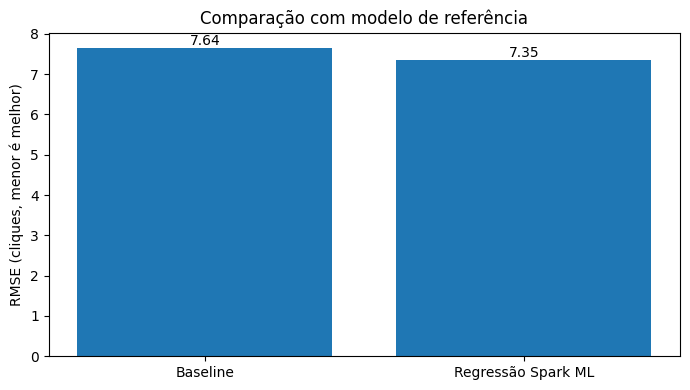

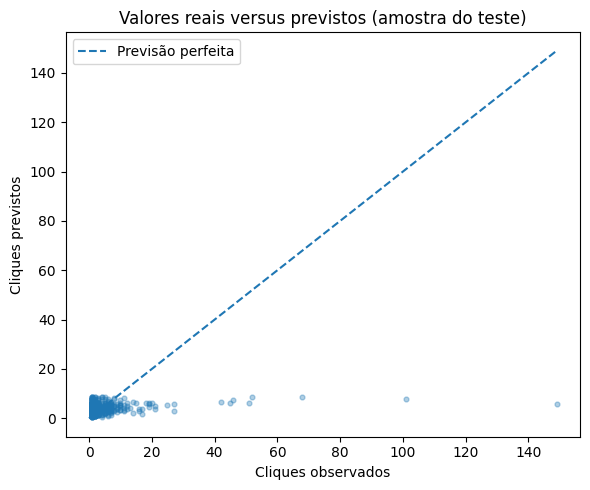

In [46]:
# Plot 1 — Comparação de desempenho.
fig, ax = plt.subplots(figsize=(7, 4))
nomes = ["Baseline", "Regressão Spark ML"]
ax.bar(nomes, [base_rmse, rmse])
ax.set_ylabel("RMSE (cliques, menor é melhor)")
ax.set_title("Comparação com modelo de referência")
for i, valor in enumerate([base_rmse, rmse]):
    ax.text(i, valor, f"{valor:.2f}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

# Plot 2 — Apenas pequena amostra das predições para visualização.
pontos = predicoes.select("label", "prediction").sample(False, 0.015, seed=SEMENTE).limit(2500).toPandas()
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(pontos["label"], pontos["prediction"], alpha=0.35, s=12)
limite = max(1.0, float(pontos[["label", "prediction"]].max().max()))
ax.plot([0, limite], [0, limite], "--", label="Previsão perfeita")
ax.set(xlabel="Cliques observados", ylabel="Cliques previstos",
       title="Valores reais versus previstos (amostra do teste)")
ax.legend()
plt.tight_layout()
plt.show()

### Interpretação e limitações

Uma redução do RMSE contra o baseline indica ganho preditivo no teste; RMSE
muito maior que MAE sugere observações com erros maiores. Previsões negativas,
quando houver, são uma limitação da regressão linear para uma contagem
não negativa. Um R² próximo de zero indica pouca explicação das variações
individuais de cliques.

**Limitações:**
1. OULAD foi construído com cursos de uma instituição e de um período histórico;
   os padrões não representam necessariamente toda a educação.
2. `sum_click` mede interação digital, **não** aprendizado, nota nem qualidade do ensino.
3. Foi utilizada uma **amostra aleatória simples de 200 mil registros** de uma
   população original de cerca de 10,65 milhões, por restrição computacional.
4. Como a seleção é por **linha**, os históricos de aluno podem estar incompletos.
   Não usamos variáveis que dependam do histórico integral.
5. O corte por estudante evita vazamento de aluno, mas não demonstra
   transferência para instituições ou períodos diferentes.
6. A regressão prevê cliques **em registros de interação existentes**, sem
   prever, por si só, a chance de um aluno não acessar os conteúdos.


In [47]:
if rmse < base_rmse and r2 > 0:
    interpretacao = (
        "A regressão superou o baseline e explicou parte da variabilidade individual. "
        "Avaliar o ganho absoluto antes de propor qualquer aplicação operacional."
    )
elif rmse < base_rmse:
    interpretacao = (
        "O erro RMSE melhorou em relação ao baseline, mas o R² não é positivo. "
        "Os atributos ainda não oferecem explicação preditiva robusta."
    )
else:
    interpretacao = (
        "A regressão não superou a previsão pela média neste teste. "
        "Há evidência insuficiente de utilidade preditiva com os atributos empregados."
    )
print("INTERPRETAÇÃO AUTOMÁTICA CONDICIONAL AOS RESULTADOS:")
print(interpretacao)
print(f"O erro absoluto médio corresponde a aproximadamente {mae:.2f} cliques por registro.")
print("Lembrete: nenhum resultado mede diretamente desempenho acadêmico.")

INTERPRETAÇÃO AUTOMÁTICA CONDICIONAL AOS RESULTADOS:
A regressão superou o baseline e explicou parte da variabilidade individual. Avaliar o ganho absoluto antes de propor qualquer aplicação operacional.
O erro absoluto médio corresponde a aproximadamente 3.19 cliques por registro.
Lembrete: nenhum resultado mede diretamente desempenho acadêmico.


## 8. Persistência com `save()` do Spark ML e verificação

O **PipelineModel completo** é salvo: indexação, codificação, padronização e
regressão. Os arquivos do modelo treinado são artefatos locais e **não** são
incluídos no repositório GitHub, conforme a regra de não publicar arquivos
de dados. Ao executar o notebook, os diretórios serão gerados automaticamente.

In [48]:
pasta_modelo = Path("modelos") / "regressao_oulad_200mil_sparkml"
pasta_modelo.parent.mkdir(exist_ok=True)
if pasta_modelo.exists():
    shutil.rmtree(pasta_modelo)
melhor_pipeline.save(str(pasta_modelo))  # save() exigido na atividade

modelo_recarregado = PipelineModel.load(str(pasta_modelo))
print("Pipeline salvo em:", pasta_modelo.resolve())
modelo_recarregado.transform(teste.limit(3)).select("label", "prediction").show()

pasta_resultados = Path("resultados")
pasta_resultados.mkdir(exist_ok=True)
resumo = {
    "dataset_kaggle": KAGGLE_DATASET,
    "origem_efetiva": origem_efetiva,
    "quantidade_original": n_original,
    "numero_colunas_interacoes": n_colunas,
    "amostra_aleatoria_sem_reposicao": n_amostra,
    "semente_amostragem": SEMENTE,
    "proporcao_amostra_pct": 100 * n_amostra / n_original,
    "apos_limpeza_e_consolidacao": n_consolidadas,
    "registros_treino": n_treino,
    "registros_teste": n_teste,
    "melhor_regParam": modelo_regressao.getRegParam(),
    "melhor_elasticNetParam": modelo_regressao.getElasticNetParam(),
    "baseline_rmse": base_rmse,
    "baseline_mae": base_mae,
    "baseline_r2": base_r2,
    "rmse": rmse,
    "mae": mae,
    "r2": r2,
    "ganho_relativo_rmse_pct": ganho_rmse_pct,
    "interpretacao": interpretacao,
}
with open(pasta_resultados / "metricas.json", "w", encoding="utf-8") as f:
    json.dump(resumo, f, ensure_ascii=False, indent=2)
print("Métricas salvas em:", pasta_resultados / "metricas.json")


Pipeline salvo em: /content/modelos/regressao_oulad_200mil_sparkml
+-----+-----------------+
|label|       prediction|
+-----+-----------------+
|  5.0|5.187605462470653|
|  1.0|5.187605462470653|
|  5.0|5.187605462470653|
+-----+-----------------+

Métricas salvas em: resultados/metricas.json


## 9. Conclusão e melhorias

Este projeto demonstra o fluxo completo **Spark ML para regressão** a partir
**do dataset aberto OULAD**, utilizando um **recorte aleatório de 200 mil
observações** da população original de aproximadamente 10,65 milhões.
Isso permite realizar a atividade em um notebook com menor custo de computação.

**A conclusão quantitativa deve ser preenchida a partir da execução real:**
compare os valores de **RMSE, MAE e R²** da regressão com o baseline da média,
e discuta os erros e as limitações.
